Importing Data + installing requried packages

In [1]:
from pathlib import Path
import pandas as pd

def find_project_root(marker=".git", start=None):
    """Walk up from the current directory until we find the repo root
    (identified by the presence of a .git folder)."""
    current = Path(start or Path.cwd()).resolve()
    for parent in [current, *current.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(
        f"Could not locate project root (no {marker} found above {current})."
    )

PROJECT_DIR = find_project_root()
DATA_DIR = PROJECT_DIR / "data" / "raw"
SUBMISSION_DIR = PROJECT_DIR / "submissions"
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

def resolve_data_file(canonical_name, fallback_name):
    """Prefer data/raw; retain compatibility with the current root-level download."""
    canonical_path = DATA_DIR / canonical_name
    fallback_path = DATA_DIR / fallback_name  # fixed: was PROJECT_DIR
    if canonical_path.exists():
        return canonical_path
    if fallback_path.exists():
        print(f"Using fallback file: {fallback_path.name}")
        return fallback_path
    raise FileNotFoundError(
        f"Could not find {canonical_path} or {fallback_path}. "
        "Place the competition CSVs in data/raw."
    )

TRAIN_PATH = resolve_data_file("train.csv", "train (1).csv")
TEST_PATH = resolve_data_file("test.csv", "test (1).csv")
SAMPLE_SUBMISSION_PATH = resolve_data_file(
    "sample_submission.csv", "sample_submission.csv"
)

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_SUBMISSION_PATH)

test_passenger_ids = test_df["PassengerId"].copy()
train_df["is_train"] = True
test_df["is_train"] = False
combined_raw = pd.concat([train_df, test_df], ignore_index=True, sort=False)

print(f"Project root: {PROJECT_DIR}")
print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Combined shape: {combined_raw.shape}")
display(sample_submission.head())

Using fallback file: train (1).csv
Using fallback file: test (1).csv
Project root: /workspaces/alpha-centauri-rescue
Train shape: (8693, 15)
Test shape: (4277, 14)
Combined shape: (12970, 15)


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


In [2]:
from pathlib import Path
from collections import Counter
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "xgboost": "xgboost",
    "lightgbm": "lightgbm",
    "catboost": "catboost",
}

for package, import_name in REQUIRED_PACKAGES.items():
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")


In [3]:
train_df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,is_train
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,True
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,True
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,True
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False,True
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False,True
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False,True


In [4]:
# 1. Extract features from the combined dataset
combined_raw['Group'] = combined_raw['PassengerId'].str.split('_').str[0]
combined_raw[['Cabin_deck', 'Cabin_num', 'Cabin_side']] = combined_raw['Cabin'].str.split('/', expand=True)
combined_raw['LastName'] = combined_raw['Name'].str.split().str[-1]

# 2. Impute HomePlanet (Chain Strategy)
# Step A: Travel Group
group_planet_map = combined_raw.dropna(subset=['HomePlanet']).groupby('Group')['HomePlanet'].first()
combined_raw.loc[combined_raw['HomePlanet'].isnull(), 'HomePlanet'] = combined_raw['Group'].map(group_planet_map)

# Step B: Family Last Name
family_planet_map = combined_raw.dropna(subset=['HomePlanet']).groupby('LastName')['HomePlanet'].first()
combined_raw.loc[combined_raw['HomePlanet'].isnull(), 'HomePlanet'] = combined_raw['LastName'].map(family_planet_map)

# Step C: Cabin Deck rules
combined_raw.loc[(combined_raw['HomePlanet'].isnull()) & (combined_raw['Cabin_deck'].isin(['A', 'B', 'C', 'T'])), 'HomePlanet'] = 'Europa'
combined_raw.loc[(combined_raw['HomePlanet'].isnull()) & (combined_raw['Cabin_deck'] == 'G'), 'HomePlanet'] = 'Earth'

# Step D: Destination Fallback
destination_mode = combined_raw.dropna(subset=['HomePlanet']).groupby('Destination')['HomePlanet'].agg(lambda x: x.mode()[0])
combined_raw.loc[combined_raw['HomePlanet'].isnull(), 'HomePlanet'] = combined_raw['Destination'].map(destination_mode)

# 3. Engineer 'FamilySize' feature
family_counts = combined_raw['LastName'].value_counts().to_dict()
combined_raw['FamilySize'] = combined_raw['LastName'].map(family_counts).fillna(0)

# 4. Clean up temporary string columns
combined_raw.drop(columns=['Name', 'LastName'], inplace=True)

# 5. Split back into train and test
train_df = combined_raw[combined_raw['is_train'] == True].copy()
test_df = combined_raw[combined_raw['is_train'] == False].copy()

# 6. Drop the split helper column and the NaN target from the test set
train_df.drop(columns=['is_train'], inplace=True)
test_df.drop(columns=['is_train', 'Transported'], inplace=True)

print(f"Cleaned Train shape: {train_df.shape}")
print(f"Cleaned Test shape: {test_df.shape}")

Cleaned Train shape: (8693, 18)
Cleaned Test shape: (4277, 17)


In [5]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

FILL NULL AND MISSING VALUES 

In [6]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [7]:
train_df['HomePlanet'].describe()


count      8693
unique        3
top       Earth
freq       4713
Name: HomePlanet, dtype: object

In [8]:
train_df['HomePlanet'].value_counts()

HomePlanet
Earth     4713
Europa    2175
Mars      1805
Name: count, dtype: int64

In [9]:
train_df['HomePlanet'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: HomePlanet
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [10]:
train_df['HomePlanet'].isna().sum()

np.int64(0)


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


<Axes: >

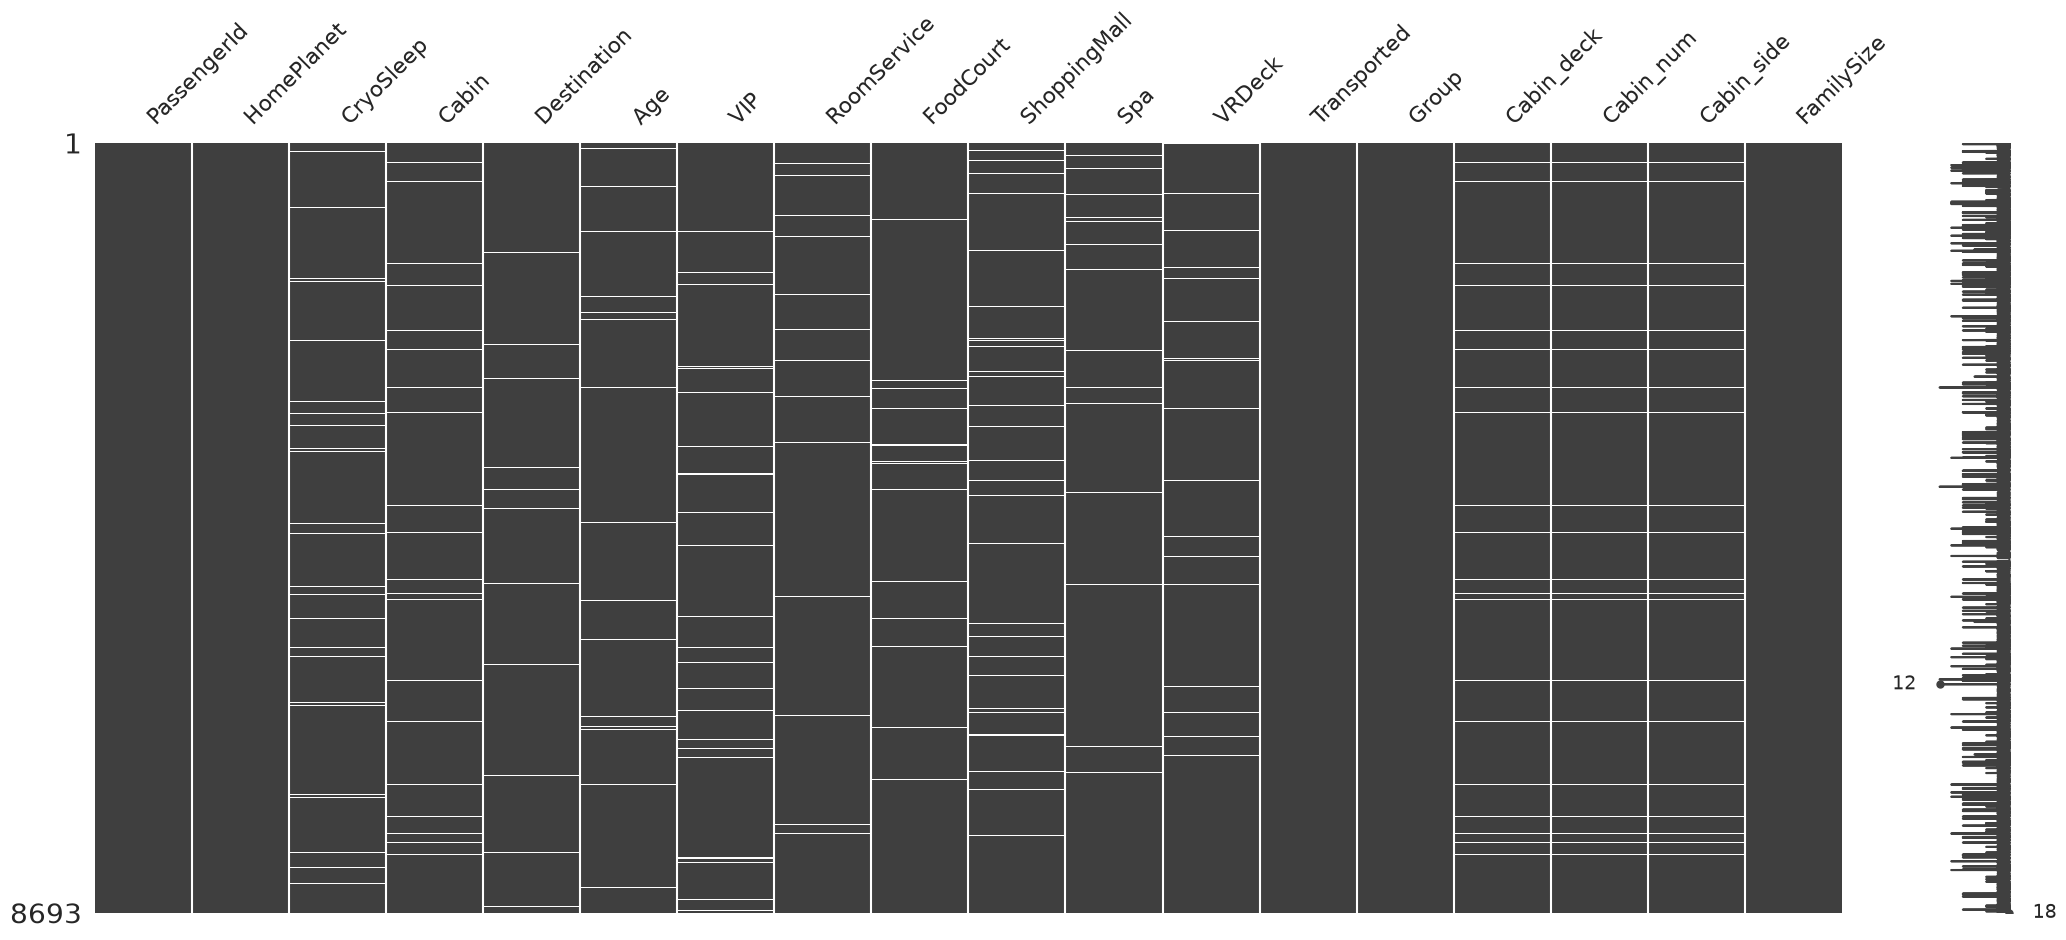

In [11]:
%pip install missingno
train_df['HomePlanet'].isna().mean() * 100
import missingno as msno
msno.matrix(train_df)

<Axes: >

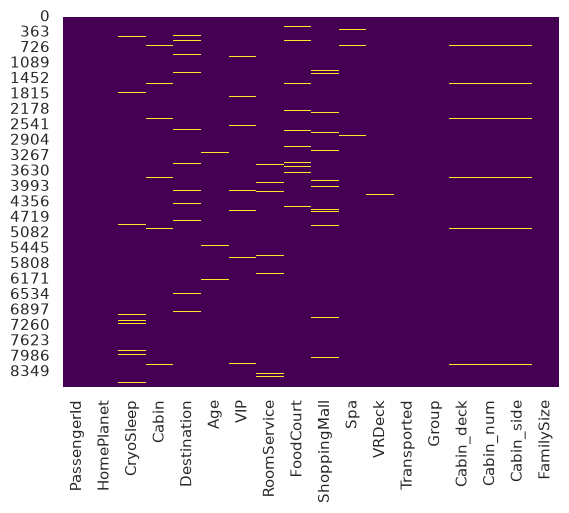

In [12]:
sns.heatmap(train_df.isna(), cbar=False, cmap='viridis')

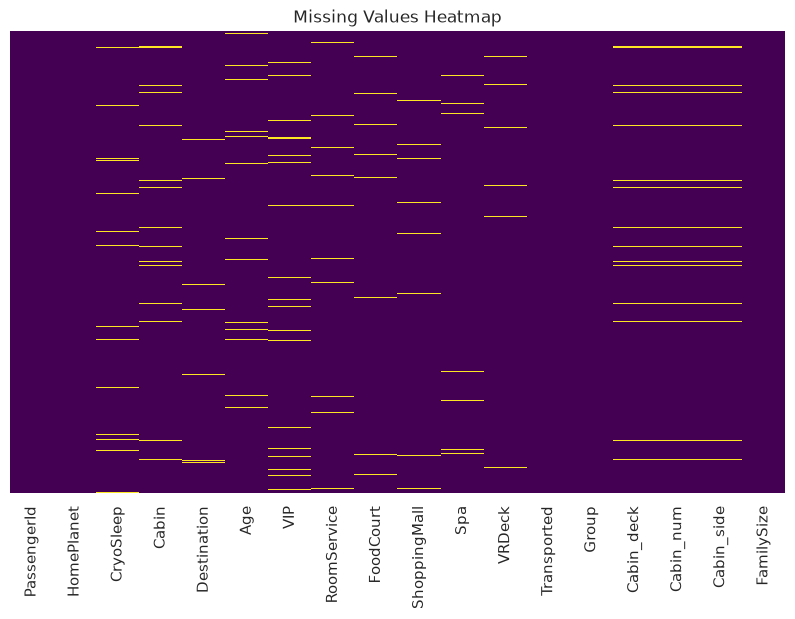

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(train_df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing Values Heatmap")
plt.show()

In [14]:
train_df['HomePlanet'] = train_df['HomePlanet'].fillna('Earth')

In [15]:
train_df['HomePlanet'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: HomePlanet
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [16]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [17]:
train_df['CryoSleep'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: CryoSleep
Non-Null Count  Dtype 
--------------  ----- 
8476 non-null   object
dtypes: object(1)
memory usage: 68.0+ KB


In [18]:
train_df['CryoSleep'].describe()
train_df['CryoSleep'].value_counts()

CryoSleep
False    5439
True     3037
Name: count, dtype: int64

In [19]:
train_df['CryoSleep'] = train_df['CryoSleep'].fillna(False)

In [20]:
train_df['CryoSleep'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: CryoSleep
Non-Null Count  Dtype 
--------------  ----- 
8693 non-null   object
dtypes: object(1)
memory usage: 68.0+ KB


In [21]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [22]:
import pandas as pd
import numpy as np

# Ensure numeric types for ordering and interpolation
combined_raw['Group_num'] = combined_raw['Group'].astype(int)
combined_raw['Cabin_num'] = pd.to_numeric(combined_raw['Cabin_num'], errors='coerce')

# -------------------------------------------------------------------------
# Phase 1: Intra-Group Imputation (Same Group Mates)
# -------------------------------------------------------------------------
# Group members almost always share Deck, Side, and base Cabin_num
group_deck_map = combined_raw.dropna(subset=['Cabin_deck']).groupby('Group')['Cabin_deck'].first()
group_side_map = combined_raw.dropna(subset=['Cabin_side']).groupby('Group')['Cabin_side'].first()
group_num_map  = combined_raw.dropna(subset=['Cabin_num']).groupby('Group')['Cabin_num'].median()

combined_raw['Cabin_deck'] = combined_raw['Cabin_deck'].fillna(combined_raw['Group'].map(group_deck_map))
combined_raw['Cabin_side'] = combined_raw['Cabin_side'].fillna(combined_raw['Group'].map(group_side_map))
combined_raw['Cabin_num']  = combined_raw['Cabin_num'].fillna(combined_raw['Group'].map(group_num_map))


# -------------------------------------------------------------------------
# Phase 2: Inter-Group Interpolation (Adjacent Group Neighbors)
# -------------------------------------------------------------------------
# Sort by Deck, Side, and Group_num to align sequential cabin blocks
combined_raw = combined_raw.sort_values(by=['Cabin_deck', 'Cabin_side', 'Group_num']).reset_index(drop=True)

# Linear interpolation estimates missing cabin numbers between adjacent groups on the same deck/side
combined_raw['Cabin_num'] = (
    combined_raw.groupby(['Cabin_deck', 'Cabin_side'])['Cabin_num']
    .transform(lambda g: g.interpolate(method='linear').ffill().bfill())
)

# Round interpolated cabin numbers back to integer floats
combined_raw['Cabin_num'] = combined_raw['Cabin_num'].round()


# -------------------------------------------------------------------------
# Phase 3: Reconstruct Unified Cabin Column & Re-sort
# -------------------------------------------------------------------------
# Re-sort back to original PassengerId order
combined_raw = combined_raw.sort_values(by='PassengerId').reset_index(drop=True)

# Rebuild complete Cabin string (e.g. 'B/0/P')
combined_raw['Cabin'] = (
    combined_raw['Cabin_deck'].astype(str) + '/' + 
    combined_raw['Cabin_num'].astype(int, errors='ignore').astype(str) + '/' + 
    combined_raw['Cabin_side'].astype(str)
)

# Clean up temporary ordering column
combined_raw.drop(columns=['Group_num'], inplace=True)

In [23]:
train_df['Cabin'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin
Non-Null Count  Dtype
--------------  -----
8494 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [24]:
train_df['Cabin'].value_counts()
train_df['Cabin'].describe()

count        8494
unique       6560
top       G/734/S
freq            8
Name: Cabin, dtype: object

Split Cabin from combined Deck/Cabin Number/Side into -cabin_deck,cabin_num and Cabin_side

In [25]:
# Extract Group ID from PassengerId
train_df['Group'] = train_df['PassengerId'].apply(lambda x: x.split('_')[0])

# Split Cabin into three separate features
train_df[['Cabin_deck', 'Cabin_num', 'Cabin_side']] = train_df['Cabin'].str.split('/', expand=True)
train_df['Cabin_num'] = train_df['Cabin_num'].astype(float)

In [26]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [27]:
train_df['Cabin_side'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_side
Non-Null Count  Dtype
--------------  -----
8494 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [28]:
train_df['Cabin_side'].describe()
train_df['Cabin_side'].value_counts()

Cabin_side
S    4288
P    4206
Name: count, dtype: int64

In [29]:
train_df['Cabin_side'] = train_df['Cabin_side'].fillna('S')  # Assuming 'S' is the most common side

In [30]:
train_df['Cabin_side'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_side
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [31]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [32]:
train_df['Cabin_num'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_num
Non-Null Count  Dtype  
--------------  -----  
8494 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [33]:
train_df['Cabin_num'].describe()
train_df['Cabin_num'].value_counts()

Cabin_num
82.0      28
19.0      22
86.0      22
56.0      21
97.0      21
          ..
1886.0     1
1891.0     1
1892.0     1
1893.0     1
1894.0     1
Name: count, Length: 1817, dtype: int64

In [34]:
train_df['Cabin_num'] = train_df['Cabin_num'].fillna(82.0)

In [35]:
train_df['Cabin_num'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_num
Non-Null Count  Dtype  
--------------  -----  
8693 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [36]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [37]:
train_df['Cabin_deck'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_deck
Non-Null Count  Dtype
--------------  -----
8494 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [38]:
train_df['Cabin_deck'].describe()
train_df['Cabin_deck'].value_counts()

Cabin_deck
F    2794
G    2559
E     876
B     779
C     747
D     478
A     256
T       5
Name: count, dtype: int64

In [39]:
train_df['Cabin_deck'] = train_df['Cabin_deck'].fillna('F')

In [40]:
train_df['Cabin_deck'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Cabin_deck
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [41]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [42]:
train_df = train_df.drop(columns=['Cabin'])

In [43]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [44]:
train_df['Destination'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Destination
Non-Null Count  Dtype
--------------  -----
8511 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [45]:
train_df['Destination'].describe()
train_df['Destination'].value_counts()

Destination
TRAPPIST-1e      5915
55 Cancri e      1800
PSO J318.5-22     796
Name: count, dtype: int64

In [46]:
train_df['Destination'] = train_df['Destination'].fillna('TRAPPIST-1e')

In [47]:
train_df['Destination'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Destination
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


In [48]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [49]:
train_df['Age'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Age
Non-Null Count  Dtype  
--------------  -----  
8514 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [50]:
train_df['Age'].describe()
train_df['Age'].value_counts()

Age
24.0    324
18.0    320
21.0    311
19.0    293
23.0    292
       ... 
72.0      4
79.0      3
78.0      3
76.0      2
77.0      2
Name: count, Length: 80, dtype: int64

In [51]:
train_df['Age'] = train_df['Age'].fillna(24.0)

In [52]:
train_df['Age'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Age
Non-Null Count  Dtype  
--------------  -----  
8693 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [53]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [54]:
train_df['VIP'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: VIP
Non-Null Count  Dtype 
--------------  ----- 
8490 non-null   object
dtypes: object(1)
memory usage: 68.0+ KB


In [55]:
train_df['VIP'].describe()
train_df['VIP'].value_counts()

VIP
False    8291
True      199
Name: count, dtype: int64

In [56]:
train_df['VIP'] = train_df['VIP'].fillna(False)

In [57]:
train_df['VIP'].info()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: VIP
Non-Null Count  Dtype 
--------------  ----- 
8693 non-null   object
dtypes: object(1)
memory usage: 68.0+ KB


In [58]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [59]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [60]:
train_df[ 'RoomService'].info()
train_df['RoomService'].describe()
train_df['RoomService'].value_counts()
train_df['RoomService'].isna().sum()
train_df['RoomService'] = train_df['RoomService'].fillna(0.0)


<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: RoomService
Non-Null Count  Dtype  
--------------  -----  
8512 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [61]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [62]:
train_df['FoodCourt'].info()
train_df['FoodCourt'].describe()
train_df['FoodCourt'].value_counts()
train_df['FoodCourt'].isna().sum()
train_df['FoodCourt'] = train_df['FoodCourt'].fillna(0.0)

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: FoodCourt
Non-Null Count  Dtype  
--------------  -----  
8510 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [63]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [64]:
train_df['ShoppingMall'].info()
train_df['ShoppingMall'].describe()
train_df['ShoppingMall'].value_counts()
train_df['ShoppingMall'] = train_df['ShoppingMall'].fillna(0.0)


<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: ShoppingMall
Non-Null Count  Dtype  
--------------  -----  
8485 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [65]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [66]:
train_df['Spa'].info()
train_df['Spa'].describe()
train_df['Spa'].value_counts()
train_df['Spa'] = train_df['Spa'].fillna(0.0)

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Spa
Non-Null Count  Dtype  
--------------  -----  
8510 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [67]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [68]:
train_df['VRDeck'].info()
train_df['VRDeck'].describe()
train_df['VRDeck'].value_counts()
train_df['VRDeck'] = train_df['VRDeck'].fillna(0.0)

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: VRDeck
Non-Null Count  Dtype  
--------------  -----  
8505 non-null   float64
dtypes: float64(1)
memory usage: 68.0 KB


In [69]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [70]:
train_df['Group'].info()
train_df['Group'].describe()
train_df['Group'].value_counts()

<class 'pandas.Series'>
RangeIndex: 8693 entries, 0 to 8692
Series name: Group
Non-Null Count  Dtype
--------------  -----
8693 non-null   str  
dtypes: str(1)
memory usage: 68.0 KB


Group
0984    8
4005    8
4256    8
4498    8
5133    8
       ..
9270    1
9274    1
9276    1
9278    1
9279    1
Name: count, Length: 6217, dtype: int64

In [71]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

HANDLING OUTLIERS

In [72]:
import numpy as np

spending_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

# 1. Fill missing financial values with 0 before transforming (CryoSleep/Infant logic usually dictates 0)
combined_raw[spending_cols] = combined_raw[spending_cols].fillna(0)

# 2. Engineer aggregate spending and active spender flag
combined_raw['TotalSpending'] = combined_raw[spending_cols].sum(axis=1)
combined_raw['HasSpent'] = (combined_raw['TotalSpending'] > 0).astype(int)

# 3. Log-transform (log1p) spending features to compress extreme values
for col in spending_cols + ['TotalSpending']:
    combined_raw[f'Log_{col}'] = np.log1p(combined_raw[col])

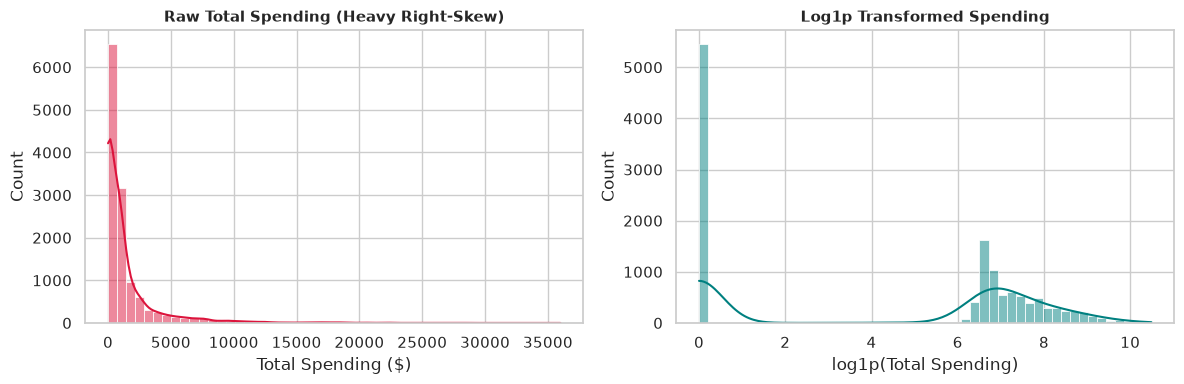

In [73]:
spending_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

# Apply treatment
combined_raw[spending_cols] = combined_raw[spending_cols].fillna(0)
combined_raw['TotalSpending'] = combined_raw[spending_cols].sum(axis=1)
combined_raw['Log_TotalSpending'] = np.log1p(combined_raw['TotalSpending'])

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(combined_raw['TotalSpending'], bins=50, kde=True, ax=axes[0], color='crimson')
axes[0].set_title("Raw Total Spending (Heavy Right-Skew)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Total Spending ($)")

sns.histplot(combined_raw['Log_TotalSpending'], bins=50, kde=True, ax=axes[1], color='teal')
axes[1].set_title("Log1p Transformed Spending", fontsize=11, fontweight='bold')
axes[1].set_xlabel("log1p(Total Spending)")

plt.tight_layout()
plt.show()

AGE OUTLIERS

In [74]:
# Cap Age at 99th percentile
upper_age_limit = combined_raw['Age'].quantile(0.99)
combined_raw['Age_Capped'] = combined_raw['Age'].clip(upper=upper_age_limit)

# Engineer age group flags (infants have different survival patterns)
combined_raw['IsInfant'] = (combined_raw['Age'] == 0).astype(int)
combined_raw['IsChild'] = (combined_raw['Age'] < 12).astype(int)

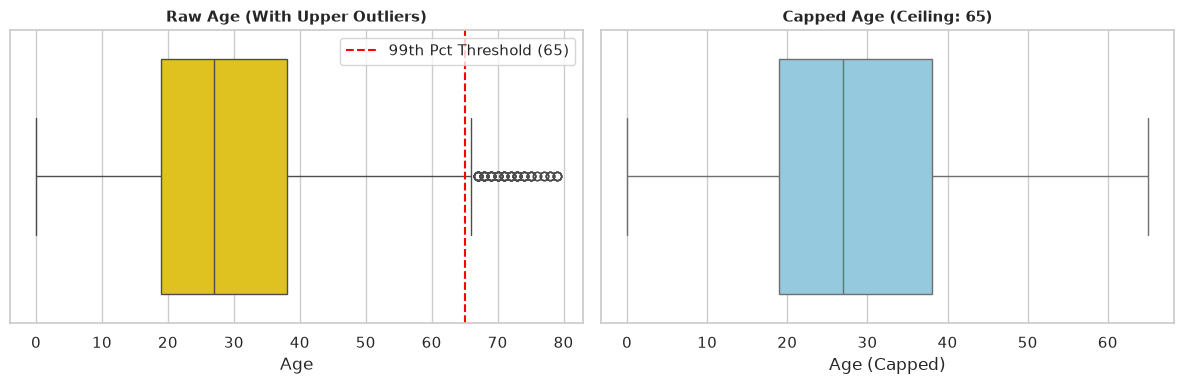

In [75]:
# Apply treatment
upper_age_limit = combined_raw['Age'].quantile(0.99)
combined_raw['Age_Capped'] = combined_raw['Age'].clip(upper=upper_age_limit)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=combined_raw['Age'], ax=axes[0], color='gold')
axes[0].axvline(upper_age_limit, color='red', linestyle='--', label=f'99th Pct Threshold ({upper_age_limit:.0f})')
axes[0].set_title("Raw Age (With Upper Outliers)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Age")
axes[0].legend()

sns.boxplot(x=combined_raw['Age_Capped'], ax=axes[1], color='skyblue')
axes[1].set_title(f"Capped Age (Ceiling: {upper_age_limit:.0f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Age (Capped)")

plt.tight_layout()
plt.show()

STRUCTURAL NUMERIC OUTLIERS

In [76]:
# Cap extreme family sizes to a ceiling of 8
combined_raw['FamilySize_Grouped'] = combined_raw['FamilySize'].clip(upper=8)

# Bin Cabin_num into spatial regions per deck (e.g., 300-cabin chunks)
combined_raw['Cabin_Region'] = combined_raw['Cabin_num'] // 300

/tmp/ipykernel_15187/2387734258.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['1', '2', '3', '4', '5', '6', '7', '8+'])


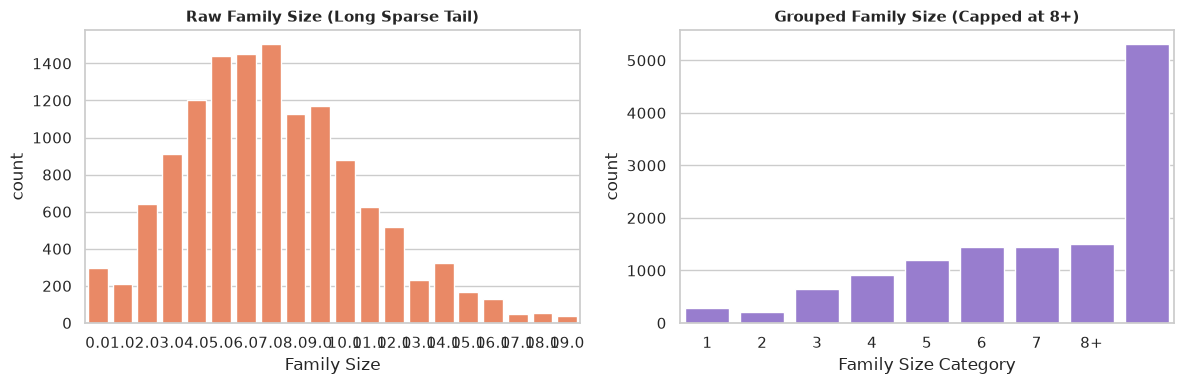

In [77]:
# Apply treatment
combined_raw['FamilySize_Grouped'] = combined_raw['FamilySize'].clip(upper=8)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x='FamilySize', data=combined_raw, ax=axes[0], color='coral')
axes[0].set_title("Raw Family Size (Long Sparse Tail)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Family Size")

sns.countplot(x='FamilySize_Grouped', data=combined_raw, ax=axes[1], color='mediumpurple')
axes[1].set_title("Grouped Family Size (Capped at 8+)", fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['1', '2', '3', '4', '5', '6', '7', '8+'])
axes[1].set_xlabel("Family Size Category")

plt.tight_layout()
plt.show()

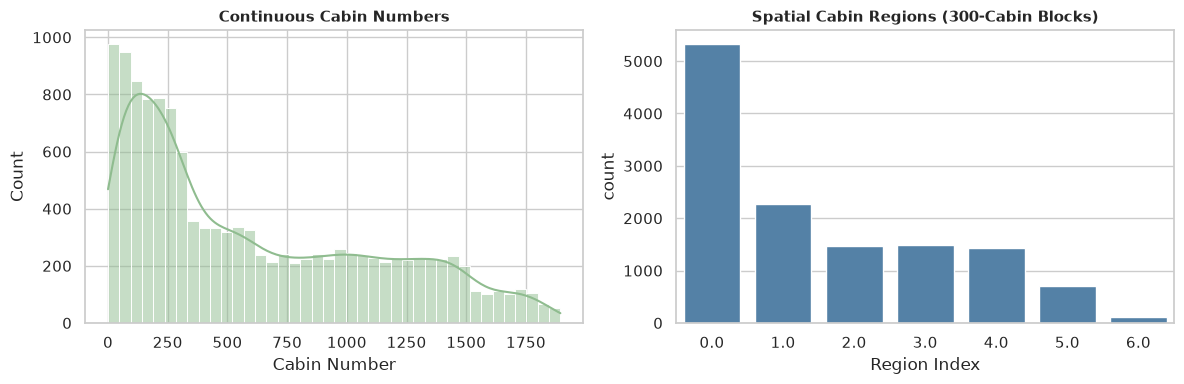

In [78]:
# Apply treatment
combined_raw['Cabin_Region'] = combined_raw['Cabin_num'] // 300

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(combined_raw['Cabin_num'], bins=40, kde=True, ax=axes[0], color='darkseagreen')
axes[0].set_title("Continuous Cabin Numbers", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Cabin Number")

sns.countplot(x='Cabin_Region', data=combined_raw, ax=axes[1], color='steelblue')
axes[1].set_title("Spatial Cabin Regions (300-Cabin Blocks)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Region Index")

plt.tight_layout()
plt.show()

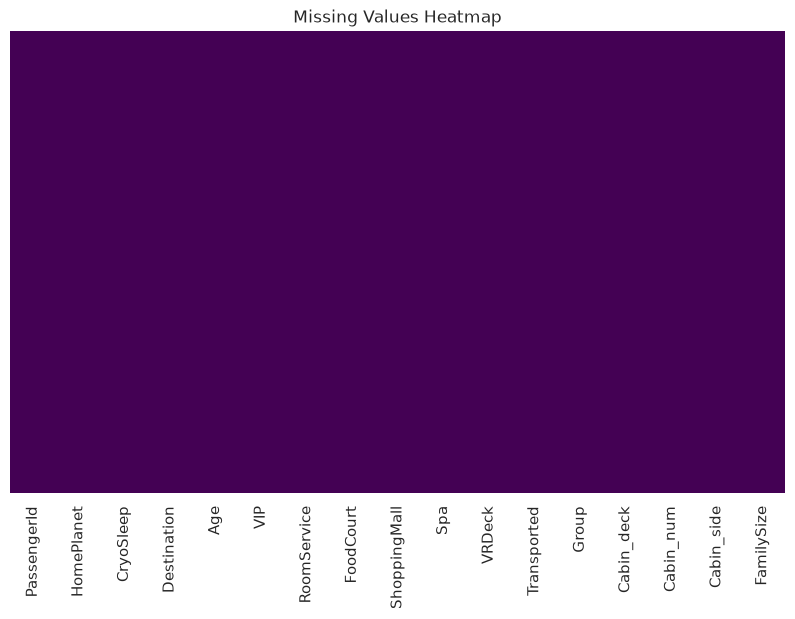

In [79]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(train_df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing Values Heatmap")
plt.show()

0:	learn: 0.7702042	test: 0.7665325	best: 0.7665325 (0)	total: 21.3ms	remaining: 21.3s
100:	learn: 0.8140638	test: 0.7993099	best: 0.7998850 (93)	total: 1.35s	remaining: 12s
200:	learn: 0.8226920	test: 0.8044853	best: 0.8044853 (198)	total: 2.4s	remaining: 9.53s
300:	learn: 0.8290193	test: 0.8090857	best: 0.8096607 (293)	total: 3.45s	remaining: 8.02s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.8113858539
bestIteration = 343

Shrink model to first 344 iterations.

Validation Set Accuracy: 0.81139

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.79      0.81       863
           1       0.80      0.83      0.82       876

    accuracy                           0.81      1739
   macro avg       0.81      0.81      0.81      1739
weighted avg       0.81      0.81      0.81      1739



/tmp/ipykernel_15187/943604092.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance.head(12), palette='viridis')


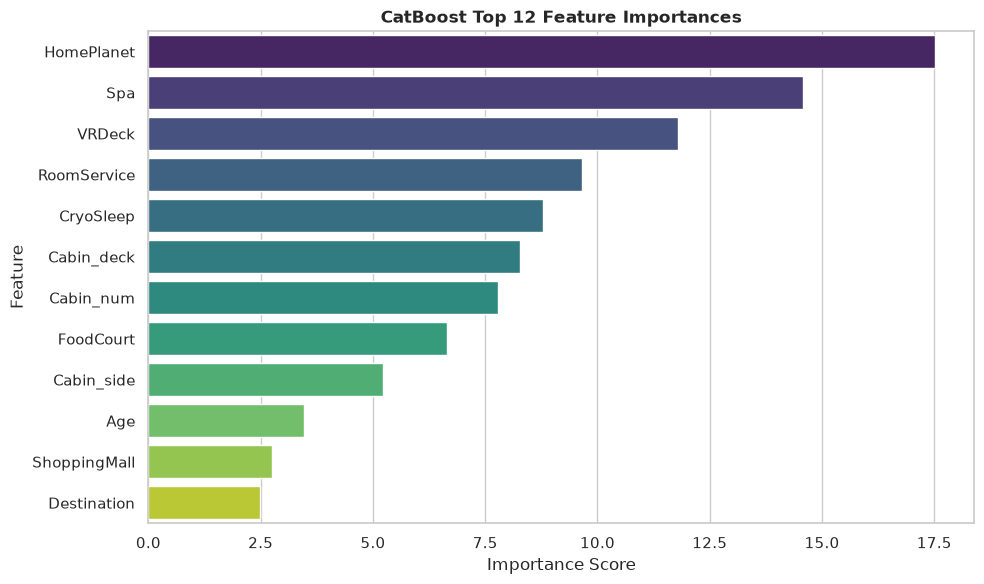

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from catboost import CatBoostClassifier

# 1. Define Target and Features
target_col = 'Transported'
exclude_cols = ['PassengerId', 'Group', target_col]
feature_cols = [col for col in train_df.columns if col not in exclude_cols]

X = train_df[feature_cols].copy()
y = train_df[target_col].astype(int)

# 2. Prepare Categorical Features for CatBoost
cat_cols = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Cabin_deck', 'Cabin_side']

# Ensure categorical features are strings and missing values are labeled
for col in cat_cols:
    if col in X.columns:
        X[col] = X[col].fillna('Missing').astype(str)

# Ensure numerical features are numeric (CatBoost natively handles missing numerical values)
num_cols = [col for col in feature_cols if col not in cat_cols]
for col in num_cols:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# 3. Train / Validation Split (80% Train, 20% Validation)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Initialize and Train CatBoost Classifier
cb_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.03,
    depth=6,
    eval_metric='Accuracy',
    random_seed=42,
    early_stopping_rounds=50,
    verbose=100
)

cb_model.fit(
    X_train, y_train,
    cat_features=cat_cols,
    eval_set=(X_val, y_val),
    use_best_model=True
)

# 5. Model Evaluation
val_preds = cb_model.predict(X_val)
val_acc = accuracy_score(y_val, val_preds)

print("\n" + "=" * 55)
print(f"Validation Set Accuracy: {val_acc:.5f}")
print("=" * 55)
print("\nClassification Report:\n", classification_report(y_val, val_preds))

# 6. Plot Top Feature Importances
feature_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': cb_model.get_feature_importance()
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance.head(12), palette='viridis')
plt.title('CatBoost Top 12 Feature Importances', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report

# =========================================================================
# STEP 1: Complete Outlier Handling & Feature Engineering (on combined_raw)
# =========================================================================

spending_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

# 1. Expenditure Outliers: Fill 0s, aggregate, and apply log1p compression
combined_raw[spending_cols] = combined_raw[spending_cols].fillna(0)
combined_raw['TotalSpending'] = combined_raw[spending_cols].sum(axis=1)
combined_raw['HasSpent'] = (combined_raw['TotalSpending'] > 0).astype(int)

for col in spending_cols + ['TotalSpending']:
    combined_raw[f'Log_{col}'] = np.log1p(combined_raw[col])

# 2. Age Outliers & Demographic Flags: Cap at 99th percentile and create flags
upper_age_limit = combined_raw['Age'].quantile(0.99)
combined_raw['Age_Capped'] = combined_raw['Age'].clip(upper=upper_age_limit)
combined_raw['IsInfant'] = (combined_raw['Age'] == 0).astype(int)
combined_raw['IsChild'] = (combined_raw['Age'] < 12).astype(int)

# 3. Family Size Outliers: Cap extreme family sizes to a max bucket of 8
combined_raw['FamilySize_Grouped'] = combined_raw['FamilySize'].clip(upper=8)

# 4. Cabin Number Outliers: Convert to numeric and bin into spatial regions (300-cabin blocks)
combined_raw['Cabin_num'] = pd.to_numeric(combined_raw['Cabin_num'], errors='coerce')
combined_raw['Cabin_Region'] = (combined_raw['Cabin_num'] // 300).fillna(-1).astype(int)

# =========================================================================
# STEP 2: Separate back into train_df and test_df
# =========================================================================

train_df = combined_raw[combined_raw['is_train'] == True].copy()
test_df = combined_raw[combined_raw['is_train'] == False].copy()

train_df.drop(columns=['is_train'], inplace=True, errors='ignore')
test_df.drop(columns=['is_train', 'Transported'], inplace=True, errors='ignore')

# =========================================================================
# STEP 3: Define Features & Prepare Categoricals for CatBoost
# =========================================================================

# Select engineered and core features
feature_cols = [
    # Categoricals
    'HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Cabin_deck', 'Cabin_side', 'Cabin_Region',
    # Numerical & Engineered
    'Age_Capped', 'IsInfant', 'IsChild', 'FamilySize_Grouped', 'Cabin_num',
    'HasSpent', 'TotalSpending', 'Log_TotalSpending',
    'Log_RoomService', 'Log_FoodCourt', 'Log_ShoppingMall', 'Log_Spa', 'Log_VRDeck'
]

cat_cols = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Cabin_deck', 'Cabin_side', 'Cabin_Region']

# Format categorical columns for CatBoost
for col in cat_cols:
    train_df[col] = train_df[col].fillna('Missing').astype(str)
    test_df[col] = test_df[col].fillna('Missing').astype(str)

X = train_df[feature_cols].copy()
y = train_df['Transported'].astype(int)
X_test = test_df[feature_cols].copy()

# =========================================================================
# STEP 4: Train CatBoost with 5-Fold Stratified Cross-Validation
# =========================================================================

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_cb = np.zeros(len(train_df))
test_preds_cb = np.zeros(len(test_df))
feature_importances = np.zeros(len(feature_cols))

cb_params = {
    'iterations': 1000,
    'learning_rate': 0.03,
    'depth': 6,
    'eval_metric': 'Accuracy',
    'random_seed': 42,
    'early_stopping_rounds': 50,
    'verbose': 0
}

print("Training CatBoost Classifier with Outlier-Treated Features...\n" + "=" * 60)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
    
    model = CatBoostClassifier(**cb_params)
    model.fit(
        X_tr, y_tr,
        cat_features=cat_cols,
        eval_set=(X_va, y_va),
        use_best_model=True
    )
    
    val_probs = model.predict_proba(X_va)[:, 1]
    oof_preds_cb[val_idx] = val_probs
    test_preds_cb += model.predict_proba(X_test)[:, 1] / skf.n_splits
    feature_importances += model.get_feature_importance() / skf.n_splits
    
    fold_acc = accuracy_score(y_va, (val_probs >= 0.5).astype(int))
    print(f"Fold {fold} Accuracy: {fold_acc:.5f}")

# Overall OOF Performance
oof_acc = accuracy_score(y, (oof_preds_cb >= 0.5).astype(int))
print("=" * 60)
print(f"Overall CatBoost Out-Of-Fold (OOF) Accuracy: {oof_acc:.5f}")
print("=" * 60)

# =========================================================================
# STEP 5: Save Submission File & Visualize Feature Importances
# =========================================================================

submission = pd.DataFrame({
    'PassengerId': test_df['PassengerId'],
    'Transported': (test_preds_cb >= 0.5).astype(bool)
})

submission_path = SUBMISSION_DIR / "catboost_outlier_engineered_sub.csv"
submission.to_csv(submission_path, index=False)
print(f"Submission file saved to: {submission_path}\n")

# Plot Feature Importances
fi_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': feature_importances
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=fi_df.head(15), palette='viridis')
plt.title('CatBoost Feature Importances (With Outlier & Region Features)', fontsize=12, fontweight='bold')
plt.xlabel('Mean Feature Importance Score')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

In [85]:
train_df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP',
       'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Transported', 'Group', 'Cabin_deck', 'Cabin_num', 'Cabin_side',
       'FamilySize'],
      dtype='str')

In [80]:
import pandas as pd
import numpy as np

# Spending columns definition
spending_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

# -------------------------------------------------------------------------
# Step 1: Domain-Driven Rule Imputation
# -------------------------------------------------------------------------

# Rule 1: If CryoSleep is True, spending MUST be 0
for col in spending_cols:
    combined_raw.loc[(combined_raw['CryoSleep'] == True) & (combined_raw[col].isnull()), col] = 0

# Rule 2: If total spending > 0, CryoSleep MUST be False
combined_raw['TempTotalSpent'] = combined_raw[spending_cols].sum(axis=1)
combined_raw.loc[(combined_raw['TempTotalSpent'] > 0) & (combined_raw['CryoSleep'].isnull()), 'CryoSleep'] = False

# Rule 3: Minors (<13) cannot spend money; Minors (<18) cannot be VIP
for col in spending_cols:
    combined_raw.loc[(combined_raw['Age'] < 13) & (combined_raw[col].isnull()), col] = 0

combined_raw.loc[(combined_raw['Age'] < 18) & (combined_raw['VIP'].isnull()), 'VIP'] = False

# -------------------------------------------------------------------------
# Step 2: Statistical Fallback Imputation
# -------------------------------------------------------------------------

# Remaining missing CryoSleep -> Impute mode based on TotalSpent == 0
cryo_mode_zero_spend = combined_raw[combined_raw['TempTotalSpent'] == 0]['CryoSleep'].mode()[0]
combined_raw['CryoSleep'] = combined_raw['CryoSleep'].fillna(cryo_mode_zero_spend)

# Remaining missing VIP -> Default to False (majority class)
combined_raw['VIP'] = combined_raw['VIP'].fillna(False)

# Remaining spending missing values -> Impute 0
combined_raw[spending_cols] = combined_raw[spending_cols].fillna(0)

# Recalculate spending aggregations and log transforms
combined_raw['TotalSpending'] = combined_raw[spending_cols].sum(axis=1)
combined_raw['HasSpent'] = (combined_raw['TotalSpending'] > 0).astype(int)

for col in spending_cols + ['TotalSpending']:
    combined_raw[f'Log_{col}'] = np.log1p(combined_raw[col])

# Remaining Age -> Impute median by HomePlanet and VIP
age_median_map = combined_raw.groupby(['HomePlanet', 'VIP'])['Age'].transform('median')
combined_raw['Age'] = combined_raw['Age'].fillna(age_median_map).fillna(combined_raw['Age'].median())

# Remaining Destination -> Impute mode
destination_mode = combined_raw['Destination'].mode()[0]
combined_raw['Destination'] = combined_raw['Destination'].fillna(destination_mode)

# Remaining Cabin_deck and Cabin_side -> Impute mode per HomePlanet
deck_mode = combined_raw.groupby('HomePlanet')['Cabin_deck'].transform(lambda x: x.mode()[0] if not x.mode().empty else 'F')
side_mode = combined_raw.groupby('HomePlanet')['Cabin_side'].transform(lambda x: x.mode()[0] if not x.mode().empty else 'S')

combined_raw['Cabin_deck'] = combined_raw['Cabin_deck'].fillna(deck_mode)
combined_raw['Cabin_side'] = combined_raw['Cabin_side'].fillna(side_mode)

# Clean up temporary helper column
combined_raw.drop(columns=['TempTotalSpent'], inplace=True)

# -------------------------------------------------------------------------
# Step 3: Feature Encoding
# -------------------------------------------------------------------------

# Convert Booleans to integers (0/1)
bool_cols = ['CryoSleep', 'VIP']
for col in bool_cols:
    combined_raw[col] = combined_raw[col].astype(int)

# Binary mapping for Cabin_side ('P' -> 0, 'S' -> 1)
combined_raw['Cabin_side'] = combined_raw['Cabin_side'].map({'P': 0, 'S': 1}).fillna(0).astype(int)

# One-Hot Encoding for nominal categoricals
ohe_cols = ['HomePlanet', 'Destination', 'Cabin_deck']
combined_encoded = pd.get_dummies(combined_raw, columns=ohe_cols, drop_first=False, dtype=int)

# -------------------------------------------------------------------------
# Step 4: Split back into Cleaned Train and Test Dataframes
# -------------------------------------------------------------------------

train_cleaned = combined_encoded[combined_encoded['is_train'] == True].copy()
test_cleaned = combined_encoded[combined_encoded['is_train'] == False].copy()

# Drop helper and target columns from test set
train_cleaned.drop(columns=['is_train', 'Cabin'], inplace=True, errors='ignore')
test_cleaned.drop(columns=['is_train', 'Transported', 'Cabin'], inplace=True, errors='ignore')

# Convert Transported target in train set to integer (0 / 1)
train_cleaned['Transported'] = train_cleaned['Transported'].astype(int)

print("Remaining Nulls in Train:", train_cleaned.isnull().sum().sum())
print("Remaining Nulls in Test:", test_cleaned.isnull().sum().sum())
print("Final Train Shape:", train_cleaned.shape)
print("Final Test Shape:", test_cleaned.shape)

Remaining Nulls in Train: 377
Remaining Nulls in Test: 217
Final Train Shape: (8693, 41)
Final Test Shape: (4277, 40)


Training CatBoost Classifier with Outlier-Treated Features...
Fold 1 Accuracy: 0.82059
Fold 2 Accuracy: 0.80909
Fold 3 Accuracy: 0.81656
Fold 4 Accuracy: 0.82221
Fold 5 Accuracy: 0.81243
Overall CatBoost Out-Of-Fold (OOF) Accuracy: 0.81617
Submission file saved to: /workspaces/alpha-centauri-rescue/submissions/catboost_outlier_engineered_sub.csv



/tmp/ipykernel_15187/4174870563.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=fi_df.head(15), palette='viridis')


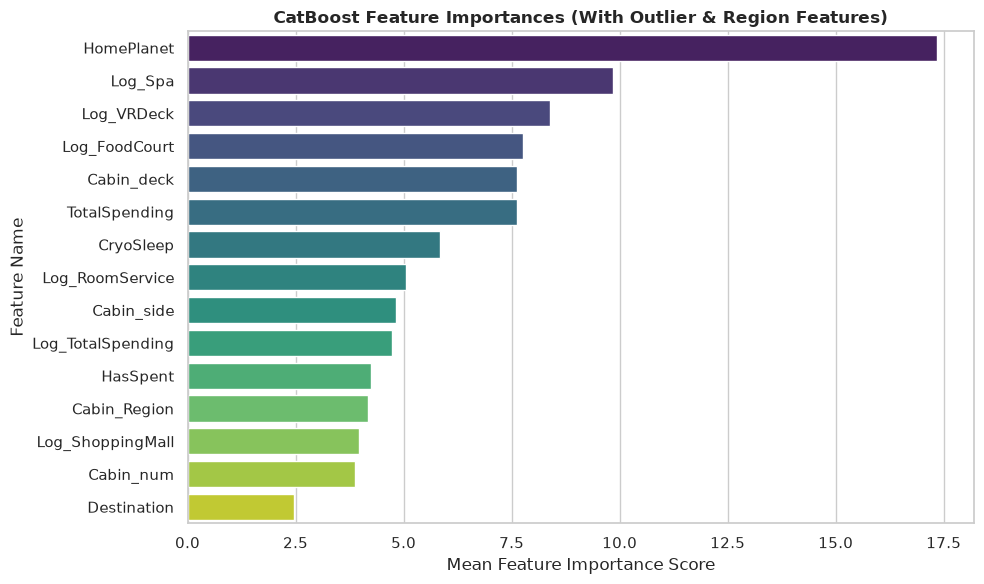

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report

# =========================================================================
# STEP 1: Complete Outlier Handling & Feature Engineering (on combined_raw)
# =========================================================================

spending_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

# 1. Expenditure Outliers: Fill 0s, aggregate, and apply log1p compression
combined_raw[spending_cols] = combined_raw[spending_cols].fillna(0)
combined_raw['TotalSpending'] = combined_raw[spending_cols].sum(axis=1)
combined_raw['HasSpent'] = (combined_raw['TotalSpending'] > 0).astype(int)

for col in spending_cols + ['TotalSpending']:
    combined_raw[f'Log_{col}'] = np.log1p(combined_raw[col])

# 2. Age Outliers & Demographic Flags: Cap at 99th percentile and create flags
upper_age_limit = combined_raw['Age'].quantile(0.99)
combined_raw['Age_Capped'] = combined_raw['Age'].clip(upper=upper_age_limit)
combined_raw['IsInfant'] = (combined_raw['Age'] == 0).astype(int)
combined_raw['IsChild'] = (combined_raw['Age'] < 12).astype(int)

# 3. Family Size Outliers: Cap extreme family sizes to a max bucket of 8
combined_raw['FamilySize_Grouped'] = combined_raw['FamilySize'].clip(upper=8)

# 4. Cabin Number Outliers: Convert to numeric and bin into spatial regions (300-cabin blocks)
combined_raw['Cabin_num'] = pd.to_numeric(combined_raw['Cabin_num'], errors='coerce')
combined_raw['Cabin_Region'] = (combined_raw['Cabin_num'] // 300).fillna(-1).astype(int)

# =========================================================================
# STEP 2: Separate back into train_df and test_df
# =========================================================================

train_df = combined_raw[combined_raw['is_train'] == True].copy()
test_df = combined_raw[combined_raw['is_train'] == False].copy()

train_df.drop(columns=['is_train'], inplace=True, errors='ignore')
test_df.drop(columns=['is_train', 'Transported'], inplace=True, errors='ignore')

# =========================================================================
# STEP 3: Define Features & Prepare Categoricals for CatBoost
# =========================================================================

# Select engineered and core features
feature_cols = [
    # Categoricals
    'HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Cabin_deck', 'Cabin_side', 'Cabin_Region',
    # Numerical & Engineered
    'Age_Capped', 'IsInfant', 'IsChild', 'FamilySize_Grouped', 'Cabin_num',
    'HasSpent', 'TotalSpending', 'Log_TotalSpending',
    'Log_RoomService', 'Log_FoodCourt', 'Log_ShoppingMall', 'Log_Spa', 'Log_VRDeck'
]

cat_cols = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Cabin_deck', 'Cabin_side', 'Cabin_Region']

# Format categorical columns for CatBoost
for col in cat_cols:
    train_df[col] = train_df[col].fillna('Missing').astype(str)
    test_df[col] = test_df[col].fillna('Missing').astype(str)

X = train_df[feature_cols].copy()
y = train_df['Transported'].astype(int)
X_test = test_df[feature_cols].copy()

# =========================================================================
# STEP 4: Train CatBoost with 5-Fold Stratified Cross-Validation
# =========================================================================

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_cb = np.zeros(len(train_df))
test_preds_cb = np.zeros(len(test_df))
feature_importances = np.zeros(len(feature_cols))

cb_params = {
    'iterations': 1000,
    'learning_rate': 0.03,
    'depth': 6,
    'eval_metric': 'Accuracy',
    'random_seed': 42,
    'early_stopping_rounds': 50,
    'verbose': 0
}

print("Training CatBoost Classifier with Outlier-Treated Features...\n" + "=" * 60)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
    
    model = CatBoostClassifier(**cb_params)
    model.fit(
        X_tr, y_tr,
        cat_features=cat_cols,
        eval_set=(X_va, y_va),
        use_best_model=True
    )
    
    val_probs = model.predict_proba(X_va)[:, 1]
    oof_preds_cb[val_idx] = val_probs
    test_preds_cb += model.predict_proba(X_test)[:, 1] / skf.n_splits
    feature_importances += model.get_feature_importance() / skf.n_splits
    
    fold_acc = accuracy_score(y_va, (val_probs >= 0.5).astype(int))
    print(f"Fold {fold} Accuracy: {fold_acc:.5f}")

# Overall OOF Performance
oof_acc = accuracy_score(y, (oof_preds_cb >= 0.5).astype(int))
print("=" * 60)
print(f"Overall CatBoost Out-Of-Fold (OOF) Accuracy: {oof_acc:.5f}")
print("=" * 60)

# =========================================================================
# STEP 5: Save Submission File & Visualize Feature Importances
# =========================================================================

submission = pd.DataFrame({
    'PassengerId': test_df['PassengerId'],
    'Transported': (test_preds_cb >= 0.5).astype(bool)
})

submission_path = SUBMISSION_DIR / "catboost_outlier_engineered_sub.csv"
submission.to_csv(submission_path, index=False)
print(f"Submission file saved to: {submission_path}\n")

# Plot Feature Importances
fi_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': feature_importances
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=fi_df.head(15), palette='viridis')
plt.title('CatBoost Feature Importances (With Outlier & Region Features)', fontsize=12, fontweight='bold')
plt.xlabel('Mean Feature Importance Score')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

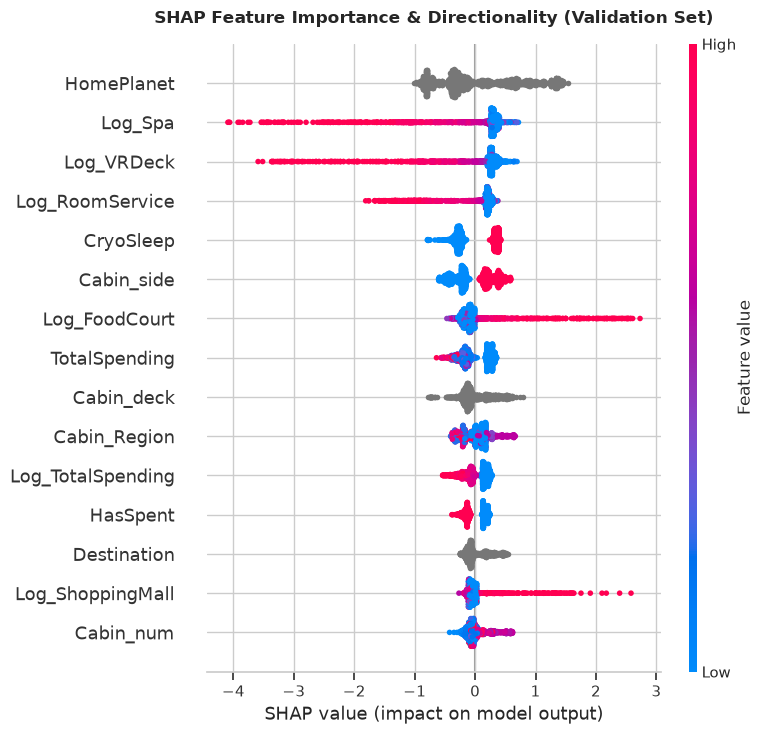

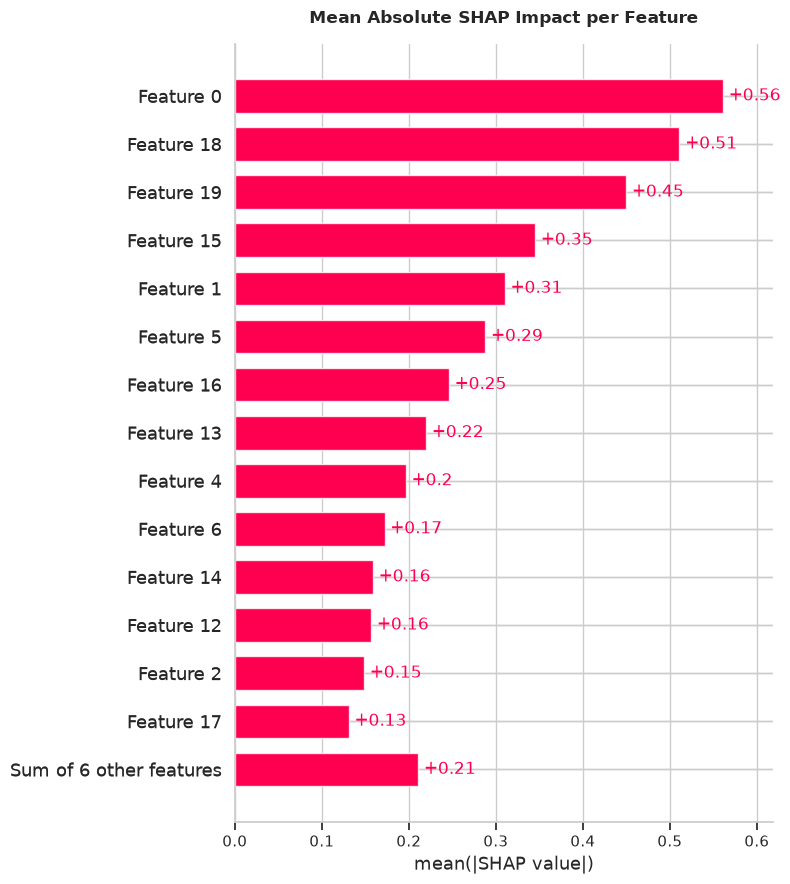

In [89]:
import shap
from catboost import Pool

# 1. Prepare CatBoost Pool for SHAP evaluation (using validation set X_va)
# Using a Pool object handles categorical string columns natively
val_pool = Pool(X_va, y_va, cat_features=cat_cols)

# 2. Initialize TreeExplainer with the trained CatBoost model
explainer = shap.TreeExplainer(model)

# 3. Calculate SHAP values for the validation set
shap_values = explainer(val_pool)

# 4. Generate SHAP Summary Beeswarm Plot (Feature Impact & Directionality)
# Shows how feature values (high vs. low) shift predictions toward Transported (True/False)
plt.figure(figsize=(10, 8))
plt.title("SHAP Feature Importance & Directionality (Validation Set)", fontsize=12, fontweight='bold', pad=15)
shap.summary_plot(
    shap_values, 
    X_va, 
    max_display=15,
    show=False
)
plt.tight_layout()
plt.show()

# 5. Generate SHAP Mean Absolute Importance Bar Plot
plt.figure(figsize=(10, 6))
plt.title("Mean Absolute SHAP Impact per Feature", fontsize=12, fontweight='bold', pad=15)
shap.plots.bar(shap_values, max_display=15, show=False)
plt.tight_layout()
plt.show()

Training CatBoost Classifier across 5 Folds...
--------------------------------------------------
Fold 1 CatBoost Accuracy: 0.81944
Fold 2 CatBoost Accuracy: 0.81426
Fold 3 CatBoost Accuracy: 0.80794
Fold 4 CatBoost Accuracy: 0.81933
Fold 5 CatBoost Accuracy: 0.79287
--------------------------------------------------
CatBoost Out-Of-Fold (OOF) Accuracy: 0.81077
XGBoost  Out-Of-Fold (OOF) Accuracy: 0.81031
Delta (CatBoost vs XGBoost):        +0.00046
--------------------------------------------------
CatBoost submission saved to: /workspaces/alpha-centauri-rescue/submissions/catboost_baseline_submission.csv



/tmp/ipykernel_15187/1178049427.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=cb_fi_df.head(15), palette='viridis')


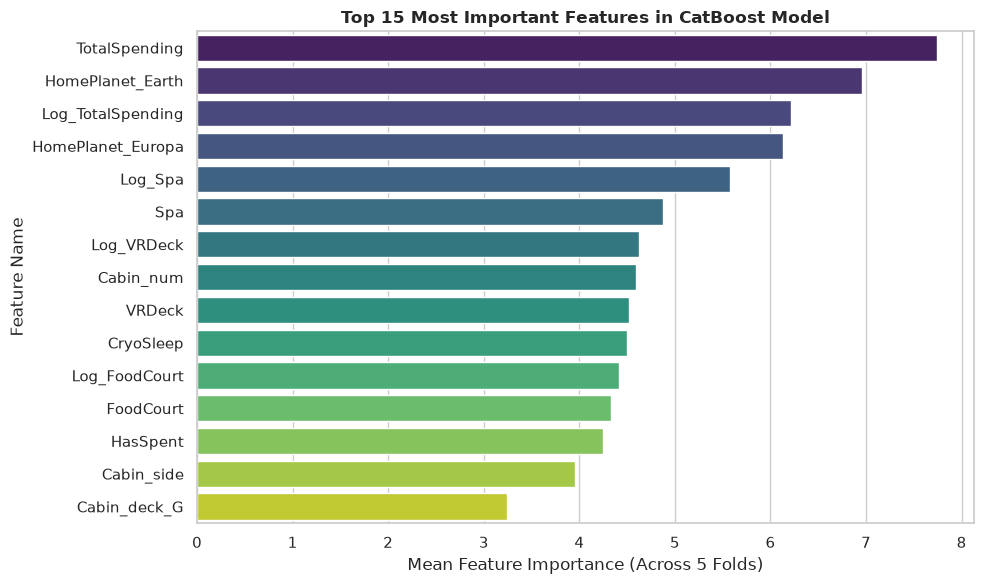

In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# 1. Align features and target with the XGBoost pipeline
exclude_cols = ['PassengerId', 'Transported', 'Group']
feature_cols = [col for col in train_cleaned.columns if col not in exclude_cols]

X = train_cleaned[feature_cols]
y = train_cleaned['Transported']
X_test = test_cleaned[feature_cols]

# 2. Configure 5-Fold Stratified Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_cb = np.zeros(len(train_cleaned))
test_preds_cb = np.zeros(len(test_cleaned))
cb_feature_importances = np.zeros(len(feature_cols))

cb_params = {
    'iterations': 1000,
    'learning_rate': 0.03,
    'depth': 6,
    'eval_metric': 'Accuracy',
    'random_seed': 42,
    'early_stopping_rounds': 50,
    'verbose': False
}

print("Training CatBoost Classifier across 5 Folds...\n" + "-" * 50)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
    
    cb_model = CatBoostClassifier(**cb_params)
    cb_model.fit(
        X_tr, y_tr,
        eval_set=(X_va, y_va),
        use_best_model=True
    )
    
    # Validation probabilities
    val_probs = cb_model.predict_proba(X_va)[:, 1]
    oof_preds_cb[val_idx] = val_probs
    
    # Accumulate test set predictions across folds
    test_preds_cb += cb_model.predict_proba(X_test)[:, 1] / skf.n_splits
    
    # Accumulate feature importances
    cb_feature_importances += cb_model.get_feature_importance() / skf.n_splits
    
    fold_acc = accuracy_score(y_va, (val_probs >= 0.5).astype(int))
    print(f"Fold {fold} CatBoost Accuracy: {fold_acc:.5f}")

# 3. Overall Out-Of-Fold Performance vs. XGBoost
oof_acc_cb = accuracy_score(y, (oof_preds_cb >= 0.5).astype(int))
print("-" * 50)
print(f"CatBoost Out-Of-Fold (OOF) Accuracy: {oof_acc_cb:.5f}")

if 'oof_acc' in globals():
    print(f"XGBoost  Out-Of-Fold (OOF) Accuracy: {oof_acc:.5f}")
    diff = oof_acc_cb - oof_acc
    print(f"Delta (CatBoost vs XGBoost):        {diff:+.5f}")
print("-" * 50)

# 4. Generate Dedicated CatBoost Submission
cb_submission = pd.DataFrame({
    'PassengerId': test_cleaned['PassengerId'],
    'Transported': (test_preds_cb >= 0.5).astype(bool)
})

cb_sub_path = SUBMISSION_DIR / "catboost_baseline_submission.csv"
cb_submission.to_csv(cb_sub_path, index=False)
print(f"CatBoost submission saved to: {cb_sub_path}\n")

# 5. Plot CatBoost Top 15 Feature Importances
cb_fi_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': cb_feature_importances
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=cb_fi_df.head(15), palette='viridis')
plt.title('Top 15 Most Important Features in CatBoost Model', fontsize=12, fontweight='bold')
plt.xlabel('Mean Feature Importance (Across 5 Folds)')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

Training LightGBM Classifier across 5 Folds...
--------------------------------------------------


/workspaces/alpha-centauri-rescue/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1 LightGBM Accuracy: 0.81139


/workspaces/alpha-centauri-rescue/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2 LightGBM Accuracy: 0.80334


...

Fold 3 LightGBM Accuracy: 0.82001


/workspaces/alpha-centauri-rescue/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4 LightGBM Accuracy: 0.81933


/workspaces/alpha-centauri-rescue/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5 LightGBM Accuracy: 0.79747

OUT-OF-FOLD (OOF) ACCURACY COMPARISON
XGBoost  OOF Accuracy: 0.81031
CatBoost OOF Accuracy: 0.81077
LightGBM OOF Accuracy: 0.81031
Blended  OOF Accuracy: 0.81330
Saved 'lightgbm_baseline_submission.csv' and 'blended_ensemble_submission.csv' to /workspaces/alpha-centauri-rescue/submissions


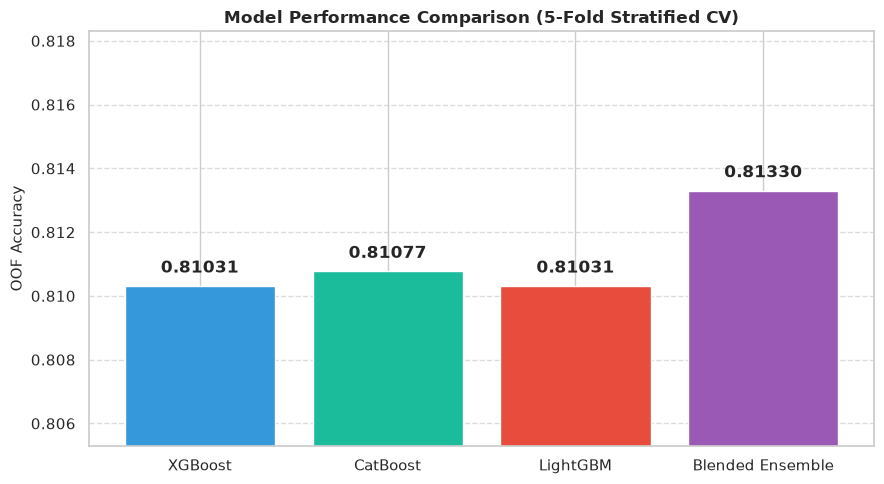

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lightgbm import LGBMClassifier, early_stopping
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# 1. Align features and target
exclude_cols = ['PassengerId', 'Transported', 'Group']
feature_cols = [col for col in train_cleaned.columns if col not in exclude_cols]

X = train_cleaned[feature_cols]
y = train_cleaned['Transported']
X_test = test_cleaned[feature_cols]

# 2. Configure 5-Fold Stratified Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_lgb = np.zeros(len(train_cleaned))
test_preds_lgb = np.zeros(len(test_cleaned))
lgb_feature_importances = np.zeros(len(feature_cols))

lgb_params = {
    'n_estimators': 1000,
    'learning_rate': 0.03,
    'max_depth': 6,
    'num_leaves': 31,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'random_state': 42,
    'verbose': -1,
    'n_jobs': -1
}

print("Training LightGBM Classifier across 5 Folds...\n" + "-" * 50)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
    
    lgb_model = LGBMClassifier(**lgb_params)
    lgb_model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    # Store OOF probabilities
    val_probs = lgb_model.predict_proba(X_va)[:, 1]
    oof_preds_lgb[val_idx] = val_probs
    
    # Accumulate test predictions across folds
    test_preds_lgb += lgb_model.predict_proba(X_test)[:, 1] / skf.n_splits
    
    # Accumulate feature importances
    lgb_feature_importances += lgb_model.feature_importances_ / skf.n_splits
    
    fold_acc = accuracy_score(y_va, (val_probs >= 0.5).astype(int))
    print(f"Fold {fold} LightGBM Accuracy: {fold_acc:.5f}")

# 3. Compute Out-Of-Fold Accuracies
acc_lgb = accuracy_score(y, (oof_preds_lgb >= 0.5).astype(int))

# Retrieve OOF predictions from previous runs if stored in memory
acc_xgb = accuracy_score(y, (oof_preds >= 0.5).astype(int)) if 'oof_preds' in globals() else None
acc_cb  = accuracy_score(y, (oof_preds_cb >= 0.5).astype(int)) if 'oof_preds_cb' in globals() else None

# Calculate equal-weighted ensemble blend across available models
if 'oof_preds' in globals() and 'oof_preds_cb' in globals():
    oof_blend = (oof_preds + oof_preds_cb + oof_preds_lgb) / 3.0
    acc_blend = accuracy_score(y, (oof_blend >= 0.5).astype(int))
    test_blend = (test_preds + test_preds_cb + test_preds_lgb) / 3.0
else:
    acc_blend = None

print("\n" + "=" * 50)
print("OUT-OF-FOLD (OOF) ACCURACY COMPARISON")
print("=" * 50)
if acc_xgb is not None: print(f"XGBoost  OOF Accuracy: {acc_xgb:.5f}")
if acc_cb  is not None: print(f"CatBoost OOF Accuracy: {acc_cb:.5f}")
print(f"LightGBM OOF Accuracy: {acc_lgb:.5f}")
if acc_blend is not None: print(f"Blended  OOF Accuracy: {acc_blend:.5f}")
print("=" * 50)

# 4. Save Submissions
lgb_sub = pd.DataFrame({
    'PassengerId': test_cleaned['PassengerId'],
    'Transported': (test_preds_lgb >= 0.5).astype(bool)
})
lgb_sub.to_csv(SUBMISSION_DIR / "lightgbm_baseline_submission.csv", index=False)

if acc_blend is not None:
    blend_sub = pd.DataFrame({
        'PassengerId': test_cleaned['PassengerId'],
        'Transported': (test_blend >= 0.5).astype(bool)
    })
    blend_sub.to_csv(SUBMISSION_DIR / "blended_ensemble_submission.csv", index=False)
    print(f"Saved 'lightgbm_baseline_submission.csv' and 'blended_ensemble_submission.csv' to {SUBMISSION_DIR}")

# 5. Comparative Visualization
model_names, accuracies = [], []

if acc_xgb is not None:
    model_names.append('XGBoost')
    accuracies.append(acc_xgb)
if acc_cb is not None:
    model_names.append('CatBoost')
    accuracies.append(acc_cb)

model_names.append('LightGBM')
accuracies.append(acc_lgb)

if acc_blend is not None:
    model_names.append('Blended Ensemble')
    accuracies.append(acc_blend)

plt.figure(figsize=(9, 5))
palette = ['#3498db', '#1abc9c', '#e74c3c', '#9b59b6'][:len(model_names)]
bars = plt.bar(model_names, accuracies, color=palette)

plt.ylim(min(accuracies) - 0.005, max(accuracies) + 0.005)
plt.ylabel('OOF Accuracy', fontsize=11)
plt.title('Model Performance Comparison (5-Fold Stratified CV)', fontsize=12, fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.0003, f"{yval:.5f}", ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

DECISION THRESHOLD OPTIMIZATION RESULTS
Default Threshold (0.50) OOF Accuracy : 0.81330
Optimal Threshold (0.4920) OOF Accuracy : 0.81422
Absolute OOF Accuracy Gain           : +0.00092 (+0.092%)
Optimized submission saved to: /workspaces/alpha-centauri-rescue/submissions/threshold_tuned_ensemble_sub_0.492.csv



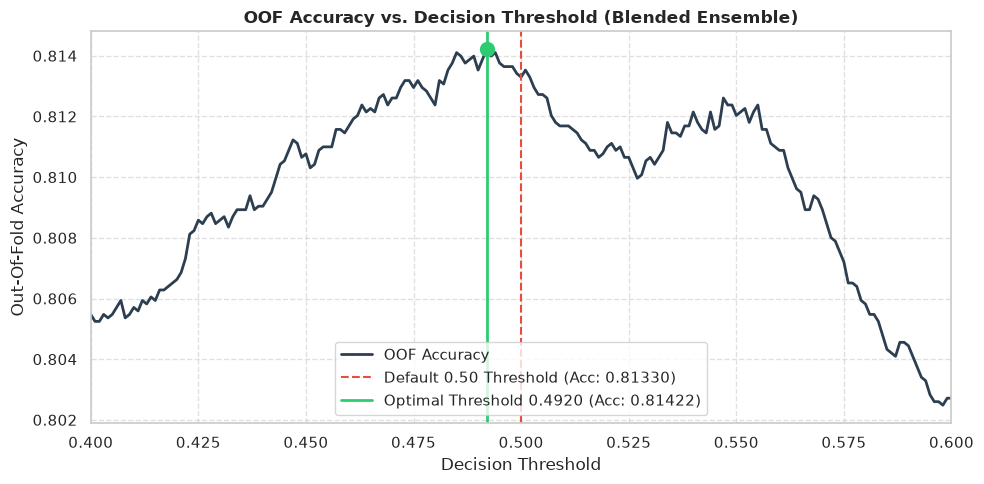

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# 1. Compute Blended Out-Of-Fold (OOF) Probabilities
# Assumes oof_preds (XGBoost), oof_preds_cb (CatBoost), and oof_preds_lgb (LightGBM) exist in memory
oof_blend = (oof_preds + oof_preds_cb + oof_preds_lgb) / 3.0
test_blend = (test_preds + test_preds_cb + test_preds_lgb) / 3.0

# 2. Define Threshold Range (0.40 to 0.60 with 0.001 resolution)
thresholds = np.linspace(0.40, 0.60, 201)
accuracies = []

# Evaluate accuracy at each decision threshold
for thresh in thresholds:
    preds_binary = (oof_blend >= thresh).astype(int)
    acc = accuracy_score(y, preds_binary)
    accuracies.append(acc)

accuracies = np.array(accuracies)

# 3. Identify Optimal Threshold
best_idx = np.argmax(accuracies)
best_threshold = thresholds[best_idx]
best_accuracy = accuracies[best_idx]

# Compare with default 0.50 threshold
default_idx = np.argmin(np.abs(thresholds - 0.50))
default_accuracy = accuracies[default_idx]
accuracy_gain = best_accuracy - default_accuracy

print("=" * 55)
print("DECISION THRESHOLD OPTIMIZATION RESULTS")
print("=" * 55)
print(f"Default Threshold (0.50) OOF Accuracy : {default_accuracy:.5f}")
print(f"Optimal Threshold ({best_threshold:.4f}) OOF Accuracy : {best_accuracy:.5f}")
print(f"Absolute OOF Accuracy Gain           : {accuracy_gain:+.5f} ({accuracy_gain*100:+.3f}%)")
print("=" * 55)

# 4. Generate Optimized Submission File
test_binary_optimized = (test_blend >= best_threshold).astype(bool)

submission_optimized = pd.DataFrame({
    'PassengerId': test_cleaned['PassengerId'],
    'Transported': test_binary_optimized
})

optimized_sub_path = SUBMISSION_DIR / f"threshold_tuned_ensemble_sub_{best_threshold:.3f}.csv"
submission_optimized.to_csv(optimized_sub_path, index=False)
print(f"Optimized submission saved to: {optimized_sub_path}\n")

# 5. Plot Threshold vs. OOF Accuracy Curve
plt.figure(figsize=(10, 5))
plt.plot(thresholds, accuracies, color='#2c3e50', linewidth=2, label='OOF Accuracy')

# Highlight default threshold (0.50)
plt.axvline(x=0.50, color='#e74c3c', linestyle='--', linewidth=1.5, 
            label=f'Default 0.50 Threshold (Acc: {default_accuracy:.5f})')

# Highlight optimal threshold
plt.axvline(x=best_threshold, color='#2ecc71', linestyle='-', linewidth=2, 
            label=f'Optimal Threshold {best_threshold:.4f} (Acc: {best_accuracy:.5f})')
plt.scatter([best_threshold], [best_accuracy], color='#2ecc71', s=100, zorder=5)

plt.title('OOF Accuracy vs. Decision Threshold (Blended Ensemble)', fontsize=12, fontweight='bold')
plt.xlabel('Decision Threshold')
plt.ylabel('Out-Of-Fold Accuracy')
plt.xlim(0.40, 0.60)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower center', frameon=True)
plt.tight_layout()
plt.show()